# PlastikTrack · Avance 1 del Proyecto Integrador
## Definición del problema, dataset y Análisis Exploratorio de Datos (EDA)

**Proyecto:** Pronóstico de demanda para distribuidoras mayoristas de bolsas, películas y desechables plásticos  
**Entregable:** Avance 1 (10 de 40 puntos)  
**Contenido:** 1) Definición del problema · 2) Dataset · 3) EDA (descriptivas, distribuciones, correlación, nulos y atípicos) · 4) Prototipo de solución

---
# 1. Definición del problema

## 1.1 Contexto del problema en la industria de los plásticos

En la cadena de suministro de plásticos de consumo (bolsas de polietileno, películas, desechables de unicel y polipropileno) el eslabón **distribuidor mayorista** abastece a miles de tiendas de abarrotes, pollerías, fondas y negocios de comida. Este eslabón tiene tres características que generan un problema operativo real:

1. **Compra en lotes mínimos.** El fabricante o importador vende por bulto, millar o caja completa, no por pieza suelta. Un error de cálculo se paga en cantidades grandes.
2. **Tiempo de reposición de 7 a 14 días.** Lo que no se pidió con anticipación no llega a tiempo para el día pico.
3. **Demanda con patrones fuertes** (días de reparto, quincena, temporadas) que el distribuidor gestiona **de memoria**, recorriendo la bodega y anotando en una libreta.

El resultado son dos fallas simultáneas que erosionan el margen:

| Falla | Qué ocurre | Costo (según la entrevista de la entrega E0) |
|---|---|---|
| **Quiebre de stock** en productos de alta rotación (bolsa camiseta, rollo) | Se pierde la venta del día pico o se compra de emergencia a otro distribuidor | Compra de emergencia ~15 % más cara; más de $2,000 MXN de utilidad neta por quiebre |
| **Sobreinventario** en productos de baja rotación (charolas, vasos, contenedor de unicel) | Cajas que se venden solo 30 % en 3 o 4 semanas; ocupan volumen en bodega | Capital inmovilizado que falta para comprar los productos que sí rotan |

**Pregunta de negocio:** ¿cuántas unidades de cada producto debe pedir el distribuidor para no quedarse sin stock en días pico y quincenas, sin inmovilizar capital en productos lentos?

**Pregunta analítica:** ¿qué patrones (día de la semana, quincena, estacionalidad mensual, tendencia y precio) explican las unidades vendidas por producto, y qué tan bien se pueden predecir con 7 y 14 días de anticipación?

## 1.2 Variable objetivo

| Elemento | Definición |
|---|---|
| **Variable objetivo** | `unidades` (unidades vendidas por producto y día) |
| **Tipo de problema** | **Regresión supervisada** (variable cuantitativa entera, no negativa) |
| **Unidad de análisis** | Un registro = un producto en un día |
| **Horizonte de predicción** | 7 y 14 días (igual al tiempo de reposición del fabricante) |
| **Variables explicativas** | `producto`, `familia`, `precio_unitario`, `dia_semana`, `es_dia_reparto`, `es_fin_de_semana`, `dia_mes`, `es_quincena`, `mes`, `trimestre`, `tendencia`, además de rezagos de ventas |

> `total` (= unidades × precio) **no** se usa como variable explicativa: contiene directamente la variable objetivo (fuga de información).

## 1.3 Justificación y valor práctico

- **Decisión que habilita:** cuánto pedir de cada producto cada semana (cantidad de reposición = demanda pronosticada durante el tiempo de entrega + stock de seguridad − inventario disponible).
- **Valor económico:** evitar quiebres en días pico (ventas y margen que hoy se pierden) y reducir el capital detenido en productos de baja rotación.
- **Por qué regresión y no clasificación:** la compra se decide en cantidades; un pronóstico numérico permite calcular el stock de seguridad con el error del modelo. Una clasificación tipo "habrá quiebre / no habrá quiebre" se puede derivar después del pronóstico, pero perdería la cantidad a pedir.
- **Métricas de éxito:** WAPE y MAE del pronóstico frente a una referencia simple (lo vendido hace 14 días), y a nivel negocio la tasa de quiebres y los días de inventario.

## 1.4 Solución propuesta

1. Limpiar y estandarizar el historial transaccional del punto de venta.
2. Entrenar un modelo de regresión que pronostique `unidades` por producto a 14 días con variables de calendario, precio y rezagos de ventas.
3. Convertir el pronóstico en una **recomendación de pedido** por producto (demanda esperada + stock de seguridad según el error del modelo).
4. Mostrarlo en el tablero de PlastikTrack (Streamlit) para que el distribuidor lo vea sin complicaciones.

Este notebook cubre los puntos 1, 2 y un **prototipo** del 3 (sección 8); el tablero ya existe desde la entrega E1.

---
# 2. Dataset y carga de datos

In [1]:
import warnings, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 40

DATA_PATH = "ventas_distribuidora.csv"
raw = pd.read_csv(DATA_PATH)
df = raw.copy()
print(f"Registros: {len(raw):,}  |  Columnas: {raw.shape[1]}")
raw.head(10)

Registros: 16,498  |  Columnas: 5


,fecha,producto,unidades,precio_unitario,total
0,2023-01-01,Bolsa Basura Todos Tamanios,3.00,41.00,123.00
1,2023-01-01,Bolsa Rollo Poliseda,1.00,33.00,33.00
2,2023-01-01,Bolsa Rollo Baja Densidad,7.00,29.50,206.50
3,2023-01-01,Bolsa Rollo Alta Densidad,7.00,36.00,252.00
4,2023-01-01,Bolsa Negra Camiseta,3.00,38.50,115.50
5,2023-01-01,Bolsa Camiseta Poliseda,4.00,35.00,140.00
6,2023-01-01,Bolsa Camiseta Plata,2.00,36.00,72.00
7,2023-01-01,Bolsa Camiseta Color,4.00,35.00,140.00
8,2023-01-01,Charolas Desechables,1.00,52.50,52.50
9,2023-01-01,Vasos Desechables,1.00,45.00,45.00


### Diccionario de datos

| Columna | Tipo | Descripción |
|---|---|---|
| `fecha` | fecha (AAAA-MM-DD) | Día de operación comercial |
| `producto` | categórica | Producto (SKU) del catálogo de la distribuidora |
| `unidades` | entera | Unidades despachadas ese día (bultos, paquetes o millares según el producto). **Variable objetivo** |
| `precio_unitario` | decimal (MXN) | Precio mayorista vigente ese día |
| `total` | decimal (MXN) | Importe del día = unidades × precio_unitario |

A partir de `fecha`, `producto` y `precio_unitario` se construyen las demás variables explicativas en la sección 4.

In [2]:
resumen = pd.DataFrame({
    "tipo": raw.dtypes.astype(str),
    "nulos": raw.isna().sum(),
    "% nulos": (raw.isna().mean() * 100).round(2),
    "valores únicos": raw.nunique(),
})
display(resumen)
print(f"Rango de fechas : {raw['fecha'].min()}  →  {raw['fecha'].max()}")
print(f"Días distintos  : {raw['fecha'].nunique():,}")
print(f"Productos (texto crudo): {raw['producto'].nunique()}")
cumple = (len(raw) >= 500)
print(f"\nRequisito ≥ 500 registros: {'CUMPLE' if cumple else 'NO CUMPLE'} ({len(raw):,})")

,tipo,nulos,% nulos,valores únicos
fecha,str,0,0.00,1369
producto,str,0,0.00,39
unidades,float64,90,0.55,121
precio_unitario,float64,12,0.07,63
total,float64,90,0.55,1796


Rango de fechas : 2023-01-01  →  2026-09-30
Días distintos  : 1,369
Productos (texto crudo): 39

Requisito ≥ 500 registros: CUMPLE (16,498)


---
# 3. Diagnóstico de calidad de datos y tratamiento

Se revisan cinco problemas típicos de un punto de venta: **inconsistencias de formato, duplicados, valores negativos, nulos y atípicos**. Para cada uno se documenta *cuántos hay*, *por qué* se considera un problema y *qué tratamiento* se propone.

## 3.1 Formato inconsistente en `producto`

In [3]:
print("Nombres distintos en el archivo crudo:", raw["producto"].nunique())
print("Nombres tras strip() + title():       ", raw["producto"].str.strip().str.title().nunique())
mask_fmt = raw["producto"] != raw["producto"].str.strip().str.title()
print(f"Registros con formato inconsistente (minúsculas, mayúsculas o espacios): {mask_fmt.sum():,} ({mask_fmt.mean()*100:.2f} %)")
display(raw.loc[mask_fmt, "producto"].map(repr).value_counts().head(8).to_frame("registros"))

Nombres distintos en el archivo crudo: 39
Nombres tras strip() + title():        12
Registros con formato inconsistente (minúsculas, mayúsculas o espacios): 70 (0.42 %)


,registros
producto,
'bolsa camiseta plata',7
'bolsa camiseta color',6
'bolsa rollo baja densidad',5
'contenedor termico unicel',5
'pelicula plastica emplaye',4
'bolsa rollo alta densidad',4
'CHAROLAS DESECHABLES',4
'bolsa basura todos tamanios',3


**Tratamiento:** quitar espacios sobrantes y normalizar a formato título. Sin esto, el mismo producto aparecería como varias categorías y se partiría su historial.

In [4]:
df["producto"] = df["producto"].str.strip().str.title()
df["fecha"] = pd.to_datetime(df["fecha"])
print("Productos únicos tras la estandarización:", df["producto"].nunique())

Productos únicos tras la estandarización: 12


## 3.2 Registros duplicados

In [5]:
dup_exactos = raw.duplicated().sum()
dup_clave = df.duplicated(subset=["fecha", "producto"], keep="first").sum()
print(f"Duplicados exactos en el crudo (fila idéntica)            : {dup_exactos:,}")
print(f"Duplicados por clave de negocio (fecha + producto), ya estandarizado: {dup_clave:,}")

Duplicados exactos en el crudo (fila idéntica)            : 70
Duplicados por clave de negocio (fecha + producto), ya estandarizado: 70


**Regla de negocio:** debe existir **un registro por producto y día**. **Tratamiento:** conservar la primera aparición y eliminar el resto; si no se eliminaran, se contarían ventas dos veces.

In [6]:
n_antes = len(df)
df = df.drop_duplicates(subset=["fecha", "producto"], keep="first").sort_values(["fecha", "producto"]).reset_index(drop=True)
print(f"Registros: {n_antes:,} → {len(df):,}  (eliminados: {n_antes-len(df):,})")
dias = df["fecha"].nunique(); prods = df["producto"].nunique()
print(f"Días × productos = {dias:,} × {prods} = {dias*prods:,}  |  registros reales = {len(df):,}  →  panel {'completo' if dias*prods==len(df) else 'con huecos'}")

Registros: 16,498 → 16,428  (eliminados: 70)
Días × productos = 1,369 × 12 = 16,428  |  registros reales = 16,428  →  panel completo


## 3.3 Variables derivadas (necesarias para el diagnóstico contextual)

In [7]:
def familia(nombre):
    n = nombre.lower()
    if "camiseta" in n: return "Bolsas camiseta"
    if "rollo" in n or "basura" in n: return "Bolsas rollo"
    return "Desechables y empaque"

DIAS = {0: "Lun", 1: "Mar", 2: "Mié", 3: "Jue", 4: "Vie", 5: "Sáb", 6: "Dom"}
ORDEN_DIAS = list(DIAS.values())

df["familia"] = df["producto"].map(familia)
df["anio"] = df["fecha"].dt.year
df["trimestre"] = df["fecha"].dt.quarter
df["mes"] = df["fecha"].dt.month
df["dia_mes"] = df["fecha"].dt.day
df["dia_semana"] = df["fecha"].dt.weekday
df["nombre_dia"] = df["dia_semana"].map(DIAS)
df["es_fin_de_semana"] = (df["dia_semana"] >= 5).astype(int)
df["es_dia_reparto"] = df["dia_semana"].isin([0, 2, 4]).astype(int)         # lunes, miércoles y viernes
df["es_quincena"] = (df["dia_mes"].between(13, 16) | (df["dia_mes"] >= 28)).astype(int)  # 13-16 y fin de mes
df["tendencia"] = (df["fecha"] - df["fecha"].min()).dt.days

df[["fecha", "producto", "familia", "dia_semana", "es_quincena", "tendencia"]].head()

,fecha,producto,familia,dia_semana,es_quincena,tendencia
0,2023-01-01,Bolsa Basura Todos Tamanios,Bolsas rollo,6,0,0
1,2023-01-01,Bolsa Camiseta Color,Bolsas camiseta,6,0,0
2,2023-01-01,Bolsa Camiseta Plata,Bolsas camiseta,6,0,0
3,2023-01-01,Bolsa Camiseta Poliseda,Bolsas camiseta,6,0,0
4,2023-01-01,Bolsa Negra Camiseta,Bolsas camiseta,6,0,0


## 3.4 Valores negativos en `unidades`

In [8]:
neg = df["unidades"] < 0
print(f"Registros con unidades negativas: {neg.sum():,}")
display(df.loc[neg, ["fecha", "producto", "unidades", "precio_unitario", "total"]].head(6))

Registros con unidades negativas: 35


,fecha,producto,unidades,precio_unitario,total
503,2023-02-11,Vasos Desechables,-3.00,45.00,-135.00
843,2023-03-12,Bolsa Camiseta Poliseda,-16.00,35.00,-560.00
1066,2023-03-30,Pelicula Plastica Emplaye,-15.00,72.50,"-1,087.50"
1136,2023-04-05,Charolas Desechables,-7.00,52.50,-367.50
1286,2023-04-18,Bolsa Camiseta Plata,-17.00,36.00,-612.00
1378,2023-04-25,Pelicula Plastica Emplaye,-9.00,72.50,-652.50


**Diagnóstico:** una venta diaria no puede ser negativa. En los datos, el valor absoluto es del orden normal de cada producto, lo que sugiere **error de captura del signo** (no devoluciones, que normalmente se registran en otro movimiento). **Tratamiento:** convertir a valor absoluto. *Alternativa si el negocio confirma que son devoluciones:* separarlas en una columna `devoluciones` y no restarlas a la demanda.

In [9]:
df.loc[neg, "unidades"] = df.loc[neg, "unidades"].abs()

## 3.5 Valores nulos

,nulos,% del total
unidades,90,0.55
precio_unitario,12,0.07
total,90,0.55


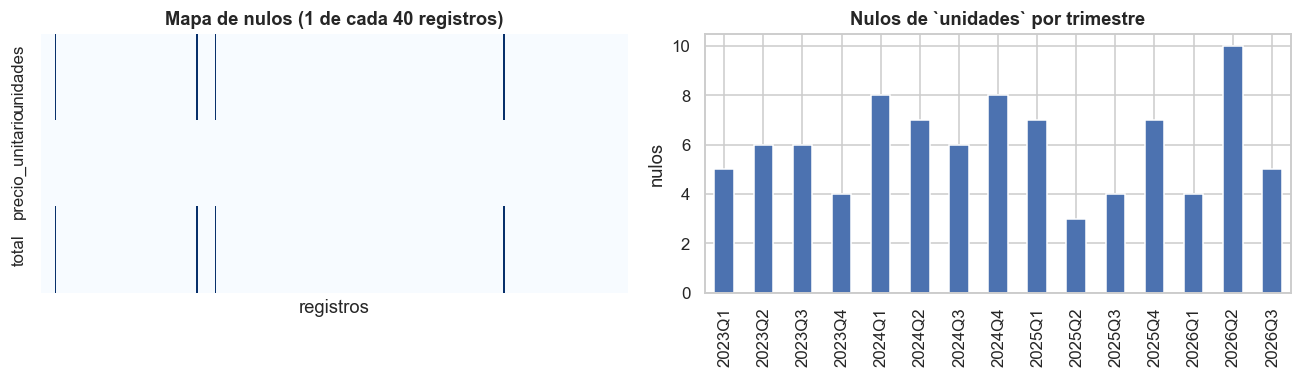

¿Los nulos se concentran en algún producto?


,nulos
producto,
Contenedor Termico Unicel,11
Vasos Desechables,11
Bolsa Rollo Poliseda,11
Bolsa Rollo Alta Densidad,9
Pelicula Plastica Emplaye,9


In [10]:
nulos = df[["unidades", "precio_unitario", "total"]].isna().sum().to_frame("nulos")
nulos["% del total"] = (nulos["nulos"] / len(df) * 100).round(3)
display(nulos)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
sns.heatmap(df[["unidades", "precio_unitario", "total"]].isna().T.astype(int).iloc[:, ::40],
            cmap="Blues", cbar=False, ax=ax[0])
ax[0].set_title("Mapa de nulos (1 de cada 40 registros)"); ax[0].set_xlabel("registros"); ax[0].set_xticks([])
(df.assign(mes=df["fecha"].dt.to_period("Q").astype(str))
   .groupby("mes")["unidades"].apply(lambda s: s.isna().sum()).plot(kind="bar", ax=ax[1], color="#4c72b0"))
ax[1].set_title("Nulos de `unidades` por trimestre"); ax[1].set_xlabel(""); ax[1].set_ylabel("nulos")
plt.tight_layout(); plt.show()

print("¿Los nulos se concentran en algún producto?")
display(df.groupby("producto")["unidades"].apply(lambda s: s.isna().sum()).sort_values(ascending=False).head(5).to_frame("nulos"))

**Diagnóstico:** los nulos están distribuidos sin patrón por producto ni por periodo (comportamiento compatible con *MCAR*: faltan al azar), por lo que no sesgan el análisis.  
**Tratamiento propuesto:**
- `unidades` nula → imputar con la **mediana del grupo (producto × día de la semana × quincena)**. Respeta los patrones semanales y de quincena; la media global los borraría. Se prefiere la mediana por su robustez ante atípicos.
- `precio_unitario` nulo → **arrastrar el último precio conocido del mismo producto** (el precio es escalonado: cambia pocas veces al año).
- `total` → **recalcular** como `unidades × precio_unitario` al final.

## 3.6 Valores atípicos (outliers)

Se contrastan dos enfoques:

1. **IQR clásico por producto** (1.5 × IQR). Es el método estándar, pero en una serie con quincenas y días pico marca como "atípico" lo que en realidad es demanda legítima.
2. **Regla contextual:** se compara cada venta contra la **mediana de su grupo** (producto × día de la semana × quincena). Se marca atípico si supera **3 veces** su mediana esperada, o si rebasa el umbral operativo de 500 unidades/día (imposible para este negocio).

IQR clásico (1.5×)  marca :   148 registros  (0.90 %)
Regla contextual    marca :    25 registros  (0.15 %)
Marcados por IQR pero NO por la regla contextual (demanda legítima en picos): 123


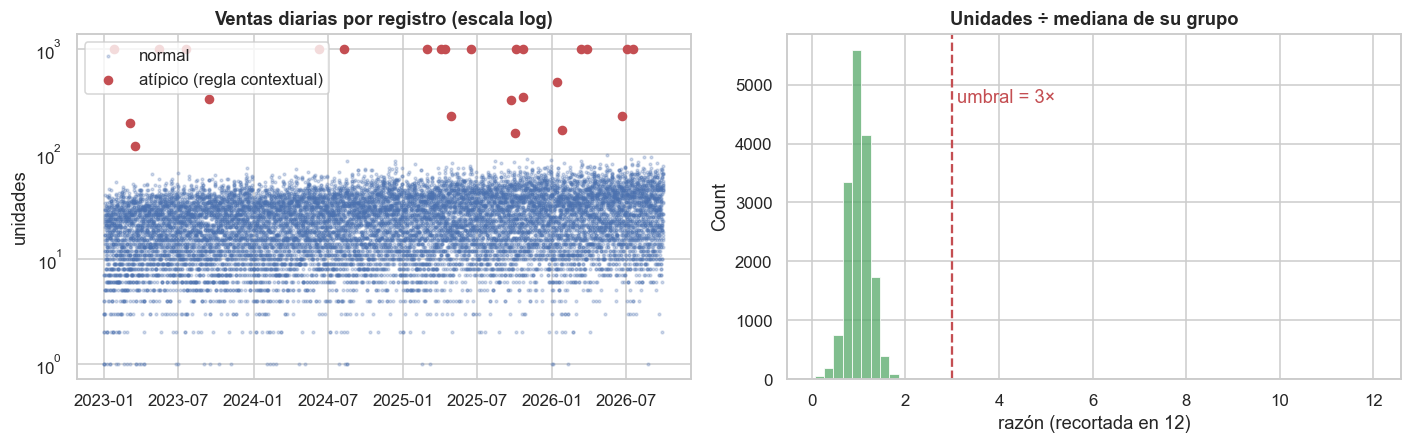

,fecha,producto,unidades,mediana_grupo,ratio_vs_grupo
15536,2026-07-18,Charolas Desechables,999.00,6.00,166.50
14193,2026-03-28,Contenedor Termico Unicel,999.00,7.50,133.20
9502,2025-03-02,Pelicula Plastica Emplaye,999.00,8.00,124.88
2408,2023-07-20,Charolas Desechables,999.00,9.00,111.00
15370,2026-07-04,Pelicula Plastica Emplaye,999.00,10.00,99.90
1617,2023-05-15,Contenedor Termico Unicel,999.00,14.00,71.36
14015,2026-03-13,Vasos Desechables,999.00,19.00,52.58
7051,2024-08-10,Bolsa Rollo Poliseda,999.00,19.00,52.58


In [11]:
keys = ["producto", "dia_semana", "es_quincena"]
validos = df[df["unidades"].notna() & (df["unidades"] > 0) & (df["unidades"] < 500)]
med_grupo = validos.groupby(keys)["unidades"].median().rename("mediana_grupo").reset_index()
df = df.drop(columns=["mediana_grupo"], errors="ignore").merge(med_grupo, on=keys, how="left")
df["ratio_vs_grupo"] = df["unidades"] / df["mediana_grupo"]

# 1) IQR clásico por producto
q1 = df.groupby("producto")["unidades"].transform(lambda s: s.quantile(0.25))
q3 = df.groupby("producto")["unidades"].transform(lambda s: s.quantile(0.75))
lim_sup = q3 + 1.5 * (q3 - q1)
df["atipico_iqr"] = df["unidades"] > lim_sup

# 2) Regla contextual
df["atipico_ctx"] = (df["unidades"] >= 500) | (df["ratio_vs_grupo"] > 3)

print(f"IQR clásico (1.5×)  marca : {df['atipico_iqr'].sum():>5,} registros  ({df['atipico_iqr'].mean()*100:.2f} %)")
print(f"Regla contextual    marca : {df['atipico_ctx'].sum():>5,} registros  ({df['atipico_ctx'].mean()*100:.2f} %)")
print(f"Marcados por IQR pero NO por la regla contextual (demanda legítima en picos): {(df['atipico_iqr'] & ~df['atipico_ctx']).sum():,}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ok = df[~df["atipico_ctx"] & df["unidades"].notna()]
ax[0].scatter(ok["fecha"], ok["unidades"], s=3, alpha=.25, color="#4c72b0", label="normal")
at = df[df["atipico_ctx"]]
ax[0].scatter(at["fecha"], at["unidades"], s=28, color="#c44e52", label="atípico (regla contextual)")
ax[0].set_yscale("log"); ax[0].set_title("Ventas diarias por registro (escala log)"); ax[0].legend(); ax[0].set_ylabel("unidades")
sns.histplot(df["ratio_vs_grupo"].dropna().clip(upper=12), bins=60, ax=ax[1], color="#55a868")
ax[1].axvline(3, color="#c44e52", ls="--"); ax[1].text(3.1, ax[1].get_ylim()[1]*.8, "umbral = 3×", color="#c44e52")
ax[1].set_title("Unidades ÷ mediana de su grupo"); ax[1].set_xlabel("razón (recortada en 12)")
plt.tight_layout(); plt.show()

display(df.loc[df["atipico_ctx"], ["fecha", "producto", "unidades", "mediana_grupo", "ratio_vs_grupo"]]
          .sort_values("ratio_vs_grupo", ascending=False).head(8))

**Diagnóstico:** los atípicos reales son de dos tipos: valores *"centinela"* (999 unidades, típico de teclear de más o de un valor por defecto del sistema) y valores **multiplicados por 10** (error de captura de un cero extra). Ambos son errores, no demanda.  
**Tratamiento propuesto:** no eliminarlos (se perdería el día completo de la serie) sino **reemplazarlos por la mediana de su grupo**, igual que los nulos. Conservar una columna `fue_imputado` para auditoría.

## 3.7 Aplicación de los tratamientos y comparación antes/después

,Problema,Registros afectados,Tratamiento
0,Formato de producto,70,strip + title()
1,Duplicados (fecha+producto),70,conservar primera aparición
2,Unidades negativas,35,valor absoluto
3,Nulos en unidades,90,mediana de producto×día×quincena
4,Nulos en precio,12,último precio conocido
5,Atípicos (regla contextual),25,mediana de producto×día×quincena



Registros crudos: 16,498  →  registros limpios: 16,428


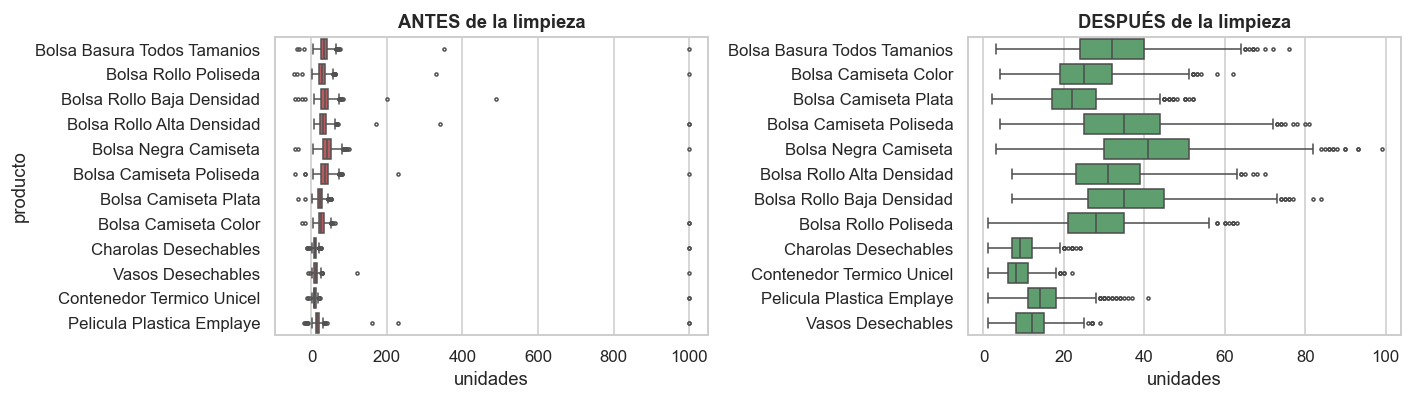

In [12]:
df["fue_imputado"] = (df["unidades"].isna() | df["atipico_ctx"]).astype(int)

# Unidades: nulos y atípicos → mediana del grupo (fallback: mediana del producto)
reemplazo = df["mediana_grupo"].fillna(df.groupby("producto")["unidades"].transform("median")).round()
df.loc[df["fue_imputado"] == 1, "unidades"] = reemplazo[df["fue_imputado"] == 1]
df["unidades"] = df["unidades"].astype(int)

# Precio: último valor conocido por producto (y hacia atrás si el primero falta)
df = df.sort_values(["producto", "fecha"])
df["precio_unitario"] = df.groupby("producto")["precio_unitario"].transform(lambda s: s.ffill().bfill())
df = df.sort_values(["fecha", "producto"]).reset_index(drop=True)

# Total consistente
df["total"] = (df["unidades"] * df["precio_unitario"]).round(2)

assert df["unidades"].isna().sum() == 0 and df["precio_unitario"].isna().sum() == 0
assert (df["unidades"] > 0).all()

resumen_limpieza = pd.DataFrame({
    "Problema": ["Formato de producto", "Duplicados (fecha+producto)", "Unidades negativas", "Nulos en unidades", "Nulos en precio", "Atípicos (regla contextual)"],
    "Registros afectados": [int(mask_fmt.sum()), int(dup_clave), int(neg.sum()), int(raw["unidades"].isna().sum()),
                            int(raw["precio_unitario"].isna().sum()), int(df["atipico_ctx"].sum())],
    "Tratamiento": ["strip + title()", "conservar primera aparición", "valor absoluto", "mediana de producto×día×quincena",
                    "último precio conocido", "mediana de producto×día×quincena"],
})
display(resumen_limpieza)
print(f"\nRegistros crudos: {len(raw):,}  →  registros limpios: {len(df):,}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=False)
sns.boxplot(data=raw.assign(producto=raw["producto"].str.strip().str.title()), x="unidades", y="producto", ax=ax[0], color="#c44e52", fliersize=2)
ax[0].set_title("ANTES de la limpieza"); ax[0].set_xlabel("unidades")
sns.boxplot(data=df, x="unidades", y="producto", ax=ax[1], color="#55a868", fliersize=2)
ax[1].set_title("DESPUÉS de la limpieza"); ax[1].set_xlabel("unidades"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

---
# 4. Variables explicativas disponibles

El dataset limpio cuenta con **más de 5 variables explicativas** (numéricas y categóricas):

In [13]:
explicativas = pd.DataFrame({
    "variable": ["producto", "familia", "precio_unitario", "dia_semana", "es_dia_reparto", "es_fin_de_semana",
                 "dia_mes", "es_quincena", "mes", "trimestre", "tendencia"],
    "tipo": ["categórica nominal", "categórica nominal", "numérica continua", "ordinal (0=lun … 6=dom)", "binaria", "binaria",
             "numérica discreta", "binaria", "ordinal (1–12)", "ordinal (1–4)", "numérica (días desde el inicio)"],
    "origen": ["dato original", "derivada de producto", "dato original", "derivada de fecha", "derivada de fecha", "derivada de fecha",
               "derivada de fecha", "derivada de fecha", "derivada de fecha", "derivada de fecha", "derivada de fecha"],
})
display(explicativas)
print(f"Total de variables explicativas: {len(explicativas)}  →  requisito ≥ 5: {'CUMPLE' if len(explicativas) >= 5 else 'NO CUMPLE'}")

,variable,tipo,origen
0,producto,categórica nominal,dato original
1,familia,categórica nominal,derivada de producto
2,precio_unitario,numérica continua,dato original
3,dia_semana,ordinal (0=lun … 6=dom),derivada de fecha
4,es_dia_reparto,binaria,derivada de fecha
5,es_fin_de_semana,binaria,derivada de fecha
6,dia_mes,numérica discreta,derivada de fecha
7,es_quincena,binaria,derivada de fecha
8,mes,ordinal (1–12),derivada de fecha
9,trimestre,ordinal (1–4),derivada de fecha


Total de variables explicativas: 11  →  requisito ≥ 5: CUMPLE


---
# 5. Estadísticas descriptivas completas

## 5.1 Variable objetivo y variables numéricas

In [14]:
num = ["unidades", "precio_unitario", "total"]
desc = df[num].describe(percentiles=[.05, .25, .5, .75, .95]).T
desc["varianza"] = df[num].var()
desc["rango"] = df[num].max() - df[num].min()
desc["IQR"] = df[num].quantile(.75) - df[num].quantile(.25)
desc["CV (%)"] = desc["std"] / desc["mean"] * 100
desc["asimetría"] = df[num].skew()
desc["curtosis"] = df[num].kurt()
desc = desc.rename(columns={"mean": "media", "50%": "mediana", "std": "desv. est.", "min": "mín", "max": "máx", "count": "n"})
display(desc[["n", "media", "mediana", "desv. est.", "varianza", "CV (%)", "mín", "5%", "25%", "75%", "95%", "máx", "rango", "IQR", "asimetría", "curtosis"]])
moda = df["unidades"].mode().iloc[0]
print(f"Moda de unidades: {moda}")

,n,media,mediana,desv. est.,varianza,CV (%),mín,5%,25%,75%,95%,máx,rango,IQR,asimetría,curtosis
unidades,"16,428.00",25.05,23.00,14.68,215.49,58.60,1.00,6.00,13.00,35.00,52.00,99.00,98.00,22.00,0.76,0.25
precio_unitario,"16,428.00",49.53,44.00,15.18,230.44,30.65,29.50,33.50,38.50,57.00,81.50,95.50,66.00,18.50,1.17,0.49
total,"16,428.00","1,136.65","1,023.50",611.24,"373,619.08",53.78,33.00,360.00,682.50,"1,479.00","2,295.00","4,801.50","4,768.50",796.50,1.03,1.43


Moda de unidades: 12


**Lectura:** si la media está por encima de la mediana y la asimetría es positiva, la distribución tiene cola derecha (pocos días de venta muy alta: quincenas y viernes). Un coeficiente de variación alto en el conjunto global se debe en buena parte a que se **mezclan productos de escala distinta** (rotación alta y baja); por eso se analiza también por producto.

## 5.2 Por producto

In [15]:
por_prod = df.groupby("producto")["unidades"].agg(["count", "mean", "median", "std", "min", "max"])
por_prod["CV (%)"] = por_prod["std"] / por_prod["mean"] * 100
por_prod["IQR"] = df.groupby("producto")["unidades"].apply(lambda s: s.quantile(.75) - s.quantile(.25))
por_prod["asimetría"] = df.groupby("producto")["unidades"].skew()
por_prod["precio medio"] = df.groupby("producto")["precio_unitario"].mean()
por_prod["ingresos totales"] = df.groupby("producto")["total"].sum()
por_prod["% ingresos"] = por_prod["ingresos totales"] / por_prod["ingresos totales"].sum() * 100
por_prod = por_prod.rename(columns={"count": "n", "mean": "media", "median": "mediana", "std": "desv. est.", "min": "mín", "max": "máx"})
display(por_prod.sort_values("media", ascending=False))

,n,media,mediana,desv. est.,mín,máx,CV (%),IQR,asimetría,precio medio,ingresos totales,% ingresos
producto,,,,,,,,,,,,
Bolsa Negra Camiseta,1369,41.82,41.00,15.11,3,99,36.13,21.00,0.50,43.90,"2,543,061.00",13.62
Bolsa Rollo Baja Densidad,1369,36.30,35.00,13.08,7,84,36.04,19.00,0.45,34.00,"1,711,788.00",9.17
Bolsa Camiseta Poliseda,1369,35.41,35.00,12.86,4,81,36.31,19.00,0.47,39.17,"1,918,906.00",10.28
Bolsa Basura Todos Tamanios,1369,32.98,32.00,11.67,3,76,35.40,16.00,0.43,46.80,"2,136,237.50",11.44
Bolsa Rollo Alta Densidad,1369,31.19,31.00,11.24,7,70,36.04,16.00,0.43,41.00,"1,770,537.00",9.48
Bolsa Rollo Poliseda,1369,28.73,28.00,10.36,1,63,36.05,14.00,0.46,37.14,"1,475,262.50",7.90
Bolsa Camiseta Color,1369,25.97,25.00,9.36,4,62,36.05,13.00,0.43,40.87,"1,470,625.50",7.88
Bolsa Camiseta Plata,1369,22.84,22.00,8.32,2,52,36.41,11.00,0.48,42.67,"1,353,615.50",7.25
Pelicula Plastica Emplaye,1369,14.84,14.00,5.68,1,41,38.31,7.00,0.53,82.84,"1,702,282.00",9.12


## 5.3 Por familia, día de la semana, quincena y mes

In [16]:
def tabla(grupo, orden=None):
    t = df.groupby(grupo)["unidades"].agg(["mean", "median", "std"]).rename(columns={"mean": "media", "median": "mediana", "std": "desv. est."})
    t["CV (%)"] = t["desv. est."] / t["media"] * 100
    return t.reindex(orden) if orden is not None else t

print("— Por familia —");      display(tabla("familia"))
print("— Por día de la semana —"); display(tabla("nombre_dia", ORDEN_DIAS))
print("— Quincena (1) vs día normal (0) —"); display(tabla("es_quincena"))
print("— Por mes —");          display(tabla("mes"))

— Por familia —


,media,mediana,desv. est.,CV (%)
familia,,,,
Bolsas camiseta,31.51,29.00,13.94,44.25
Bolsas rollo,32.30,31.00,11.95,37.00
Desechables y empaque,11.34,11.00,5.20,45.84


— Por día de la semana —


,media,mediana,desv. est.,CV (%)
nombre_dia,,,,
Lun,31.69,32.00,16.04,50.62
Mar,24.34,24.00,12.21,50.16
Mié,30.09,30.00,15.16,50.37
Jue,24.00,24.00,12.15,50.62
Vie,33.36,34.00,16.67,49.99
Sáb,17.85,18.00,9.06,50.79
Dom,14.02,14.00,7.16,51.08


— Quincena (1) vs día normal (0) —


,media,mediana,desv. est.,CV (%)
es_quincena,,,,
0,23.43,21.00,13.41,57.21
1,30.06,27.00,17.12,56.97


— Por mes —


,media,mediana,desv. est.,CV (%)
mes,,,,
1,22.02,20.00,13.67,62.06
2,22.66,21.00,13.75,60.71
3,23.97,22.00,14.04,58.60
4,25.44,23.00,14.71,57.82
5,26.01,23.00,14.72,56.58
6,25.55,23.00,14.48,56.68
7,25.27,23.00,14.82,58.65
8,25.52,23.00,15.27,59.84
9,26.30,24.00,15.12,57.47


## 5.4 Variables categóricas

In [17]:
print("Frecuencia por producto:")
display(df["producto"].value_counts().to_frame("registros").assign(porcentaje=lambda d: d["registros"] / d["registros"].sum() * 100).T)
print("Frecuencia por familia:")
display(df["familia"].value_counts().to_frame("registros").assign(porcentaje=lambda d: d["registros"] / d["registros"].sum() * 100).T)
print(f"Días de quincena: {df.drop_duplicates('fecha')['es_quincena'].mean()*100:.1f} % de los días del calendario")

Frecuencia por producto:


producto,Bolsa Basura Todos Tamanios,Bolsa Camiseta Color,Bolsa Camiseta Plata,Bolsa Camiseta Poliseda,Bolsa Negra Camiseta,Bolsa Rollo Alta Densidad,Bolsa Rollo Baja Densidad,Bolsa Rollo Poliseda,Charolas Desechables,Contenedor Termico Unicel,Pelicula Plastica Emplaye,Vasos Desechables
registros,"1,369.00","1,369.00","1,369.00","1,369.00","1,369.00","1,369.00","1,369.00","1,369.00","1,369.00","1,369.00","1,369.00","1,369.00"
porcentaje,8.33,8.33,8.33,8.33,8.33,8.33,8.33,8.33,8.33,8.33,8.33,8.33


Frecuencia por familia:


familia,Bolsas rollo,Bolsas camiseta,Desechables y empaque
registros,"5,476.00","5,476.00","5,476.00"
porcentaje,33.33,33.33,33.33


Días de quincena: 24.4 % de los días del calendario


---
# 6. Visualización de distribuciones

## 6.1 Distribución de la variable objetivo

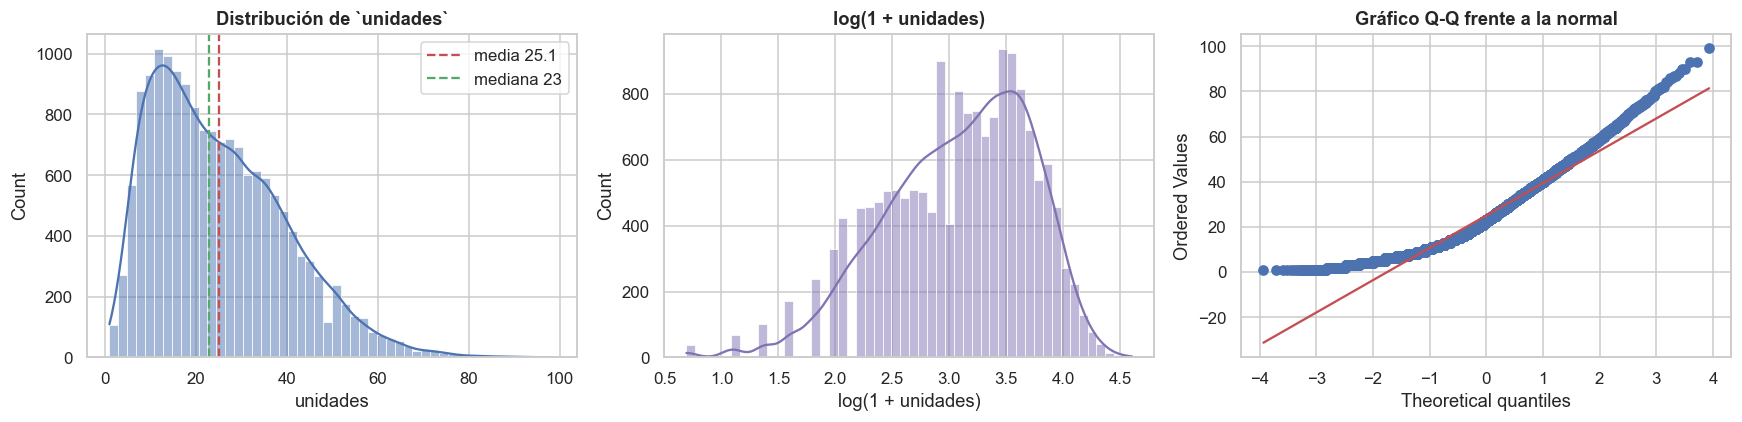

Prueba de normalidad (Shapiro-Wilk, muestra de ≤5,000): p = 1.99e-38  →  se rechaza normalidad


In [18]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["unidades"], bins=50, kde=True, ax=ax[0], color="#4c72b0")
ax[0].axvline(df["unidades"].mean(), color="#c44e52", ls="--", label=f"media {df['unidades'].mean():.1f}")
ax[0].axvline(df["unidades"].median(), color="#55a868", ls="--", label=f"mediana {df['unidades'].median():.0f}")
ax[0].legend(); ax[0].set_title("Distribución de `unidades`")

sns.histplot(np.log1p(df["unidades"]), bins=50, kde=True, ax=ax[1], color="#8172b2")
ax[1].set_title("log(1 + unidades)"); ax[1].set_xlabel("log(1 + unidades)")

stats.probplot(df["unidades"], dist="norm", plot=ax[2])
ax[2].set_title("Gráfico Q-Q frente a la normal")
plt.tight_layout(); plt.show()

sw_muestra = df["unidades"].sample(min(5000, len(df)), random_state=1)
print("Prueba de normalidad (Shapiro-Wilk, muestra de ≤5,000): p = {:.2e}  →  {}".format(
    stats.shapiro(sw_muestra).pvalue, "se rechaza normalidad" if stats.shapiro(sw_muestra).pvalue < .05 else "compatible con normal"))

**Implicación para el modelado:** la distribución global no es normal (mezcla de productos de escalas distintas y cola derecha). Conviene modelar **por producto** o incluir `producto` como variable, y evaluar con métricas relativas (WAPE) además de errores absolutos.

## 6.2 Distribución por producto

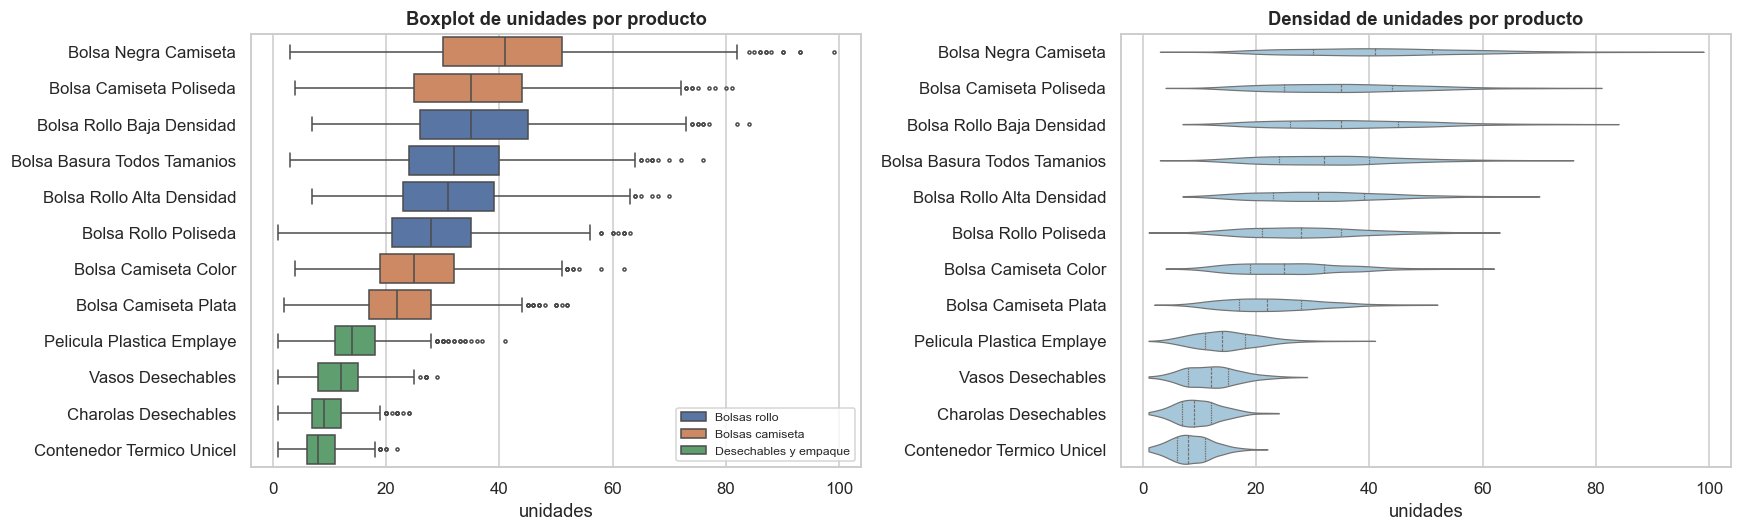

In [19]:
orden_prod = df.groupby("producto")["unidades"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=df, y="producto", x="unidades", order=orden_prod, hue="familia", dodge=False, ax=ax[0], fliersize=2)
ax[0].set_title("Boxplot de unidades por producto"); ax[0].set_ylabel(""); ax[0].legend(title="", loc="lower right", fontsize=8)
sns.violinplot(data=df, y="producto", x="unidades", order=orden_prod, ax=ax[1], cut=0, inner="quartile", color="#9ecae1", linewidth=.8)
ax[1].set_title("Densidad de unidades por producto"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

## 6.3 Distribución de `precio_unitario` y su evolución

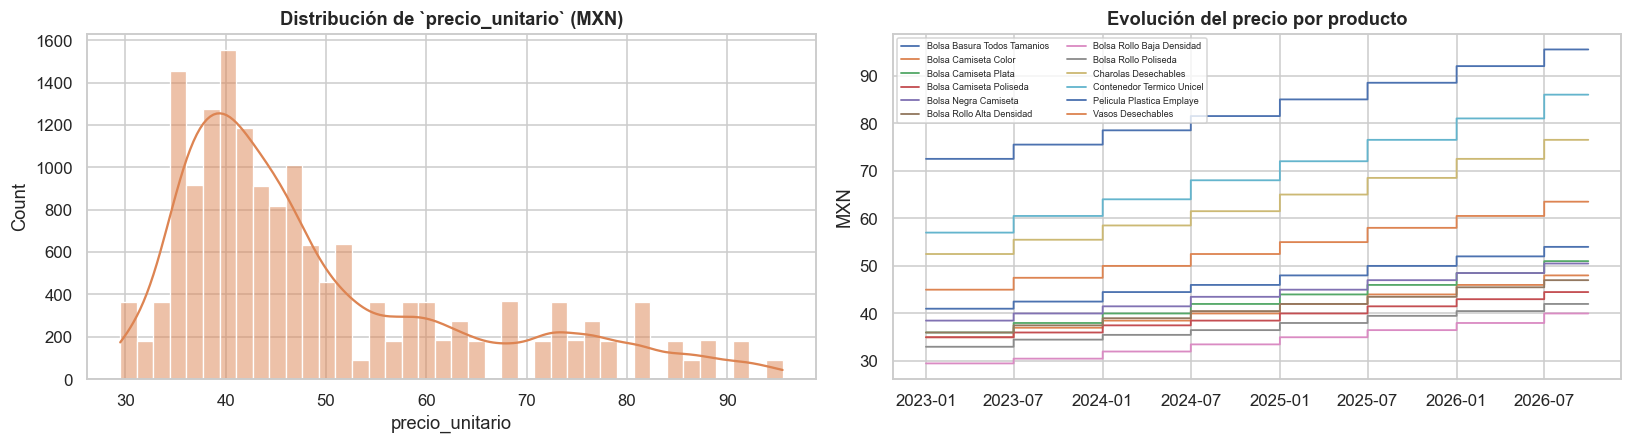

Cambios de precio detectados por producto:


producto,Bolsa Basura Todos Tamanios,Bolsa Camiseta Color,Bolsa Camiseta Plata,Bolsa Camiseta Poliseda,Bolsa Negra Camiseta,Bolsa Rollo Alta Densidad,Bolsa Rollo Baja Densidad,Bolsa Rollo Poliseda,Charolas Desechables,Contenedor Termico Unicel,Pelicula Plastica Emplaye,Vasos Desechables
cambios de precio,7,7,7,7,7,7,7,7,7,7,7,7


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
sns.histplot(df["precio_unitario"], bins=40, kde=True, ax=ax[0], color="#dd8452"); ax[0].set_title("Distribución de `precio_unitario` (MXN)")
for p, g in df.groupby("producto"):
    ax[1].step(g["fecha"], g["precio_unitario"], where="post", lw=1.2, label=p)
ax[1].set_title("Evolución del precio por producto"); ax[1].set_ylabel("MXN"); ax[1].legend(fontsize=6, ncol=2)
plt.tight_layout(); plt.show()

cambios = df.sort_values(["producto", "fecha"]).groupby("producto")["precio_unitario"].apply(lambda s: (s.diff().abs() > 0).sum())
print("Cambios de precio detectados por producto:"); display(cambios.to_frame("cambios de precio").T)

## 6.4 Patrones temporales: semana, quincena, mes y tendencia

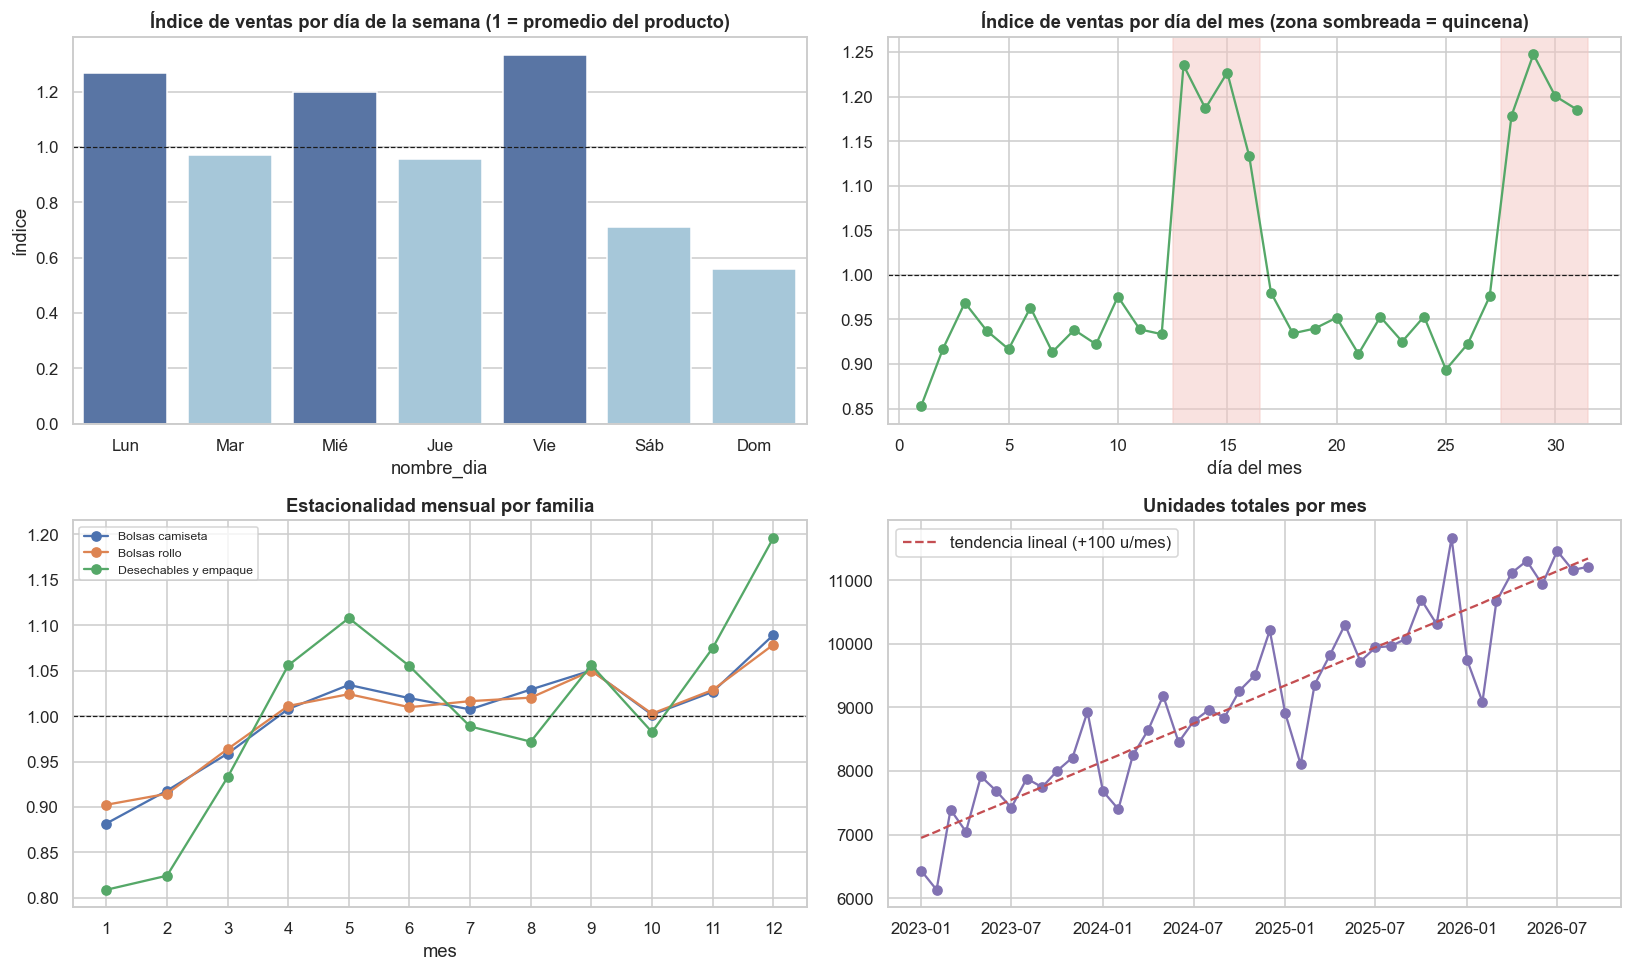

In [21]:
fig, ax = plt.subplots(2, 2, figsize=(15, 9))

# Día de la semana (índice vs promedio del propio producto, para poder juntar productos de distinta escala)
df["unid_rel"] = df["unidades"] / df.groupby("producto")["unidades"].transform("mean")
sem = df.groupby("nombre_dia")["unid_rel"].mean().reindex(ORDEN_DIAS)
sns.barplot(x=sem.index, y=sem.values, ax=ax[0, 0], palette=["#4c72b0" if d in ("Lun", "Mié", "Vie") else "#9ecae1" for d in sem.index])
ax[0, 0].axhline(1, color="k", lw=.8, ls="--"); ax[0, 0].set_title("Índice de ventas por día de la semana (1 = promedio del producto)"); ax[0, 0].set_ylabel("índice")

# Día del mes
dm = df.groupby("dia_mes")["unid_rel"].mean()
ax[0, 1].plot(dm.index, dm.values, marker="o", color="#55a868"); ax[0, 1].axhline(1, color="k", lw=.8, ls="--")
for a, b in [(13, 16), (28, 31)]: ax[0, 1].axvspan(a - .5, b + .5, color="#f4c7c3", alpha=.5)
ax[0, 1].set_title("Índice de ventas por día del mes (zona sombreada = quincena)"); ax[0, 1].set_xlabel("día del mes")

# Mes
mes = df.groupby(["mes", "familia"])["unid_rel"].mean().unstack()
mes.plot(marker="o", ax=ax[1, 0]); ax[1, 0].axhline(1, color="k", lw=.8, ls="--")
ax[1, 0].set_title("Estacionalidad mensual por familia"); ax[1, 0].set_xticks(range(1, 13)); ax[1, 0].legend(title="", fontsize=8)

# Serie temporal total mensual
serie = df.groupby(df["fecha"].dt.to_period("M"))["unidades"].sum()
serie.index = serie.index.to_timestamp()
ax[1, 1].plot(serie.index, serie.values, marker="o", color="#8172b2")
z = np.polyfit(np.arange(len(serie)), serie.values, 1); ax[1, 1].plot(serie.index, np.polyval(z, np.arange(len(serie))), "--", color="#c44e52", label=f"tendencia lineal ({z[0]:+.0f} u/mes)")
ax[1, 1].set_title("Unidades totales por mes"); ax[1, 1].legend()
plt.tight_layout(); plt.show()

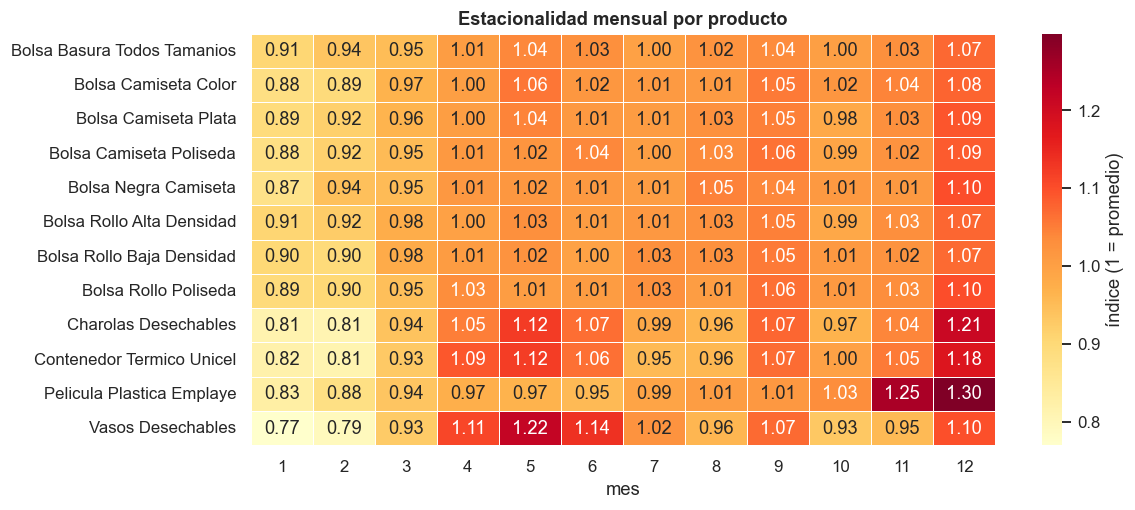

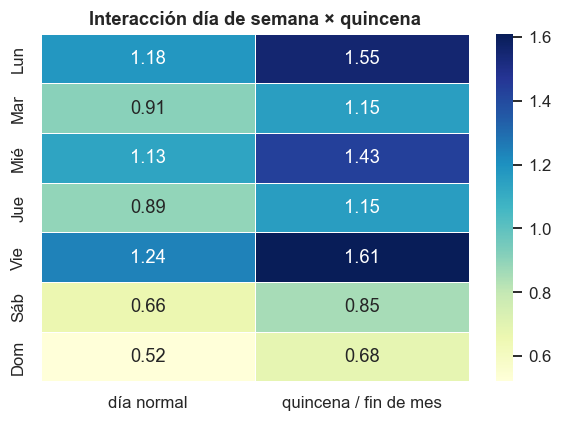

In [22]:
# Mapa de calor: producto × mes (índice relativo)
piv = df.pivot_table(index="producto", columns="mes", values="unid_rel", aggfunc="mean")
plt.figure(figsize=(11, 4.8))
sns.heatmap(piv, cmap="YlOrRd", annot=True, fmt=".2f", cbar_kws={"label": "índice (1 = promedio)"}, linewidths=.4)
plt.title("Estacionalidad mensual por producto"); plt.ylabel(""); plt.tight_layout(); plt.show()

# Mapa de calor: día de la semana × quincena
piv2 = df.pivot_table(index="nombre_dia", columns="es_quincena", values="unid_rel", aggfunc="mean").reindex(ORDEN_DIAS)
piv2.columns = ["día normal", "quincena / fin de mes"]
plt.figure(figsize=(5.5, 4)); sns.heatmap(piv2, cmap="YlGnBu", annot=True, fmt=".2f", linewidths=.4)
plt.title("Interacción día de semana × quincena"); plt.ylabel(""); plt.tight_layout(); plt.show()

## 6.5 Autocorrelación de la serie diaria

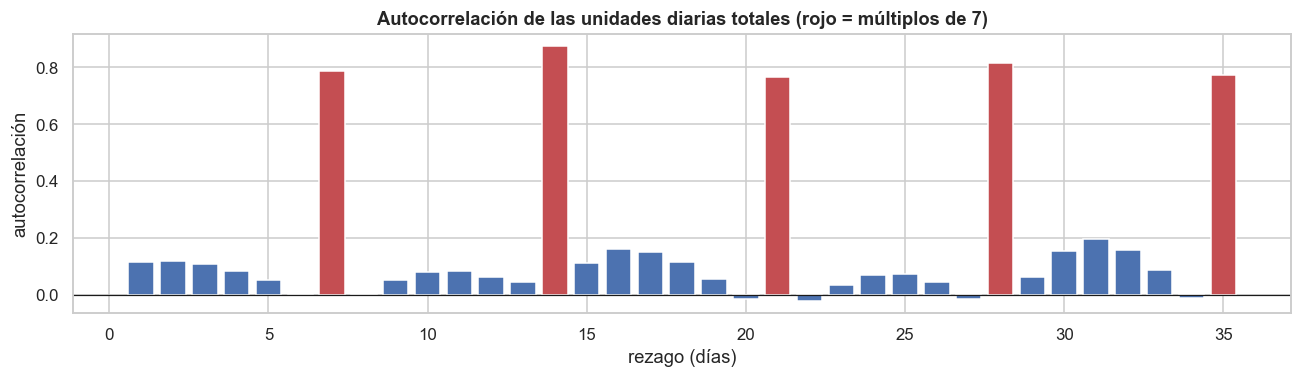

In [23]:
diaria = df.groupby("fecha")["unidades"].sum()
acf = [diaria.autocorr(l) for l in range(1, 36)]
plt.figure(figsize=(12, 3.6))
plt.bar(range(1, 36), acf, color=["#c44e52" if l in (7, 14, 21, 28, 35) else "#4c72b0" for l in range(1, 36)])
plt.axhline(0, color="k", lw=.8); plt.title("Autocorrelación de las unidades diarias totales (rojo = múltiplos de 7)")
plt.xlabel("rezago (días)"); plt.ylabel("autocorrelación"); plt.tight_layout(); plt.show()

**Implicación para el modelado:** si los rezagos 7, 14, 21… sobresalen, la demanda tiene memoria semanal. Esto justifica usar como variable el rezago de **14 días**: es información que el distribuidor ya conoce al momento de pedir con 14 días de anticipación, sin filtración de datos del futuro.

---
# 7. Correlaciones y pruebas estadísticas

## 7.1 Matriz de correlación (mapa de calor)

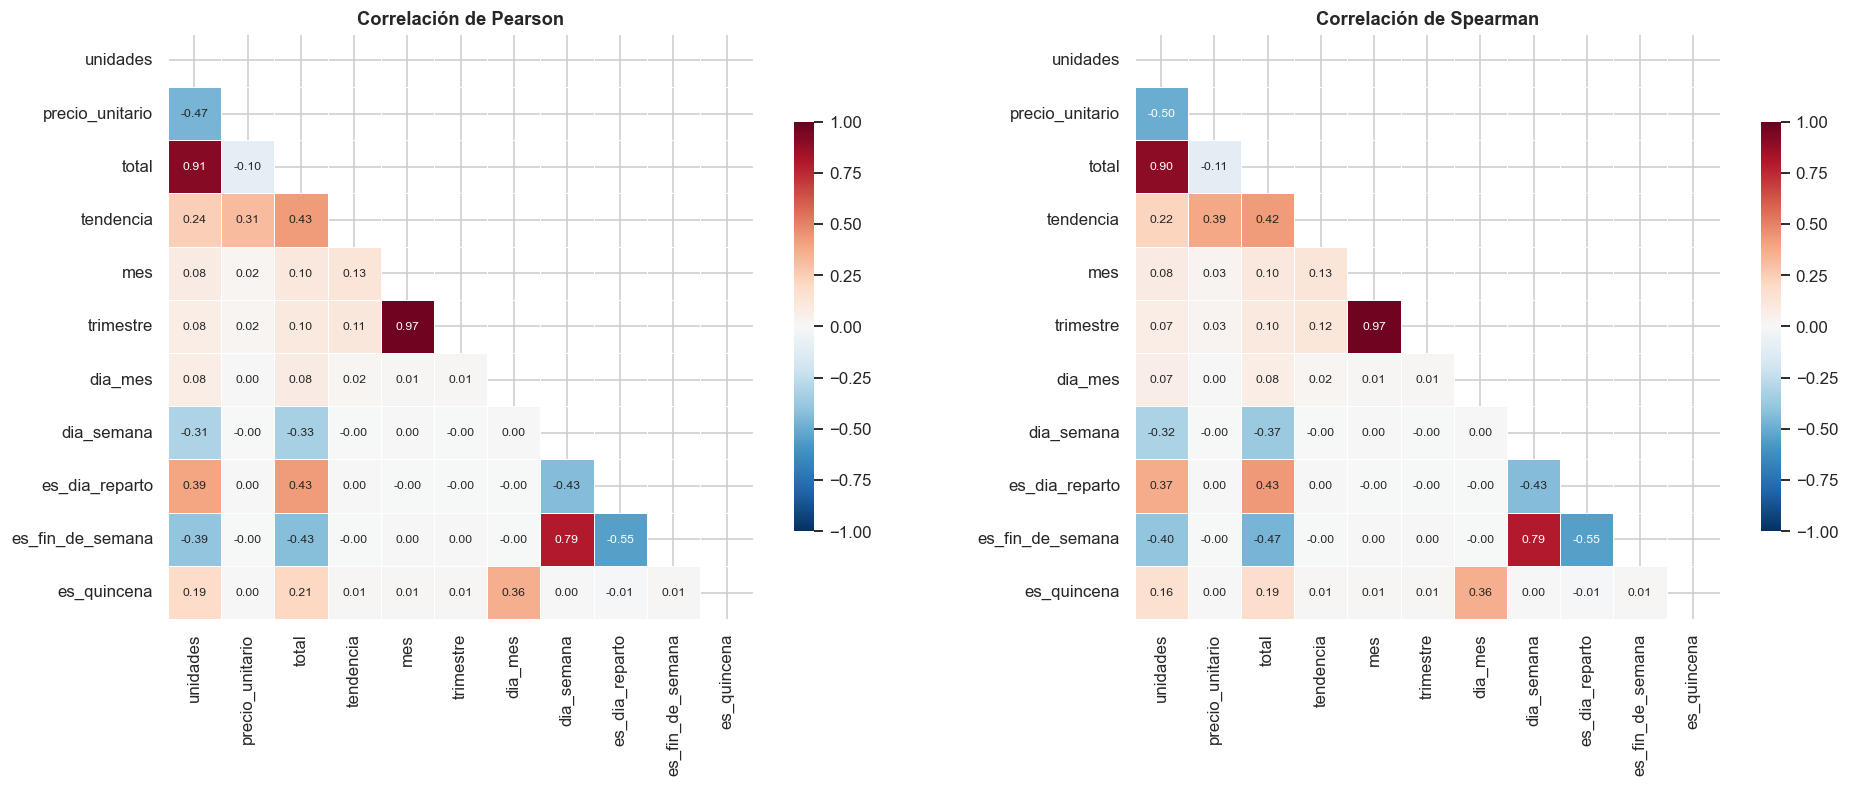

In [24]:
vars_corr = ["unidades", "precio_unitario", "total", "tendencia", "mes", "trimestre", "dia_mes",
             "dia_semana", "es_dia_reparto", "es_fin_de_semana", "es_quincena"]
fig, ax = plt.subplots(1, 2, figsize=(18, 7))
for a, met in zip(ax, ["pearson", "spearman"]):
    corr = df[vars_corr].corr(method=met)
    sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), cmap="RdBu_r", vmin=-1, vmax=1, center=0,
                annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=.4, square=True, cbar_kws={"shrink": .7}, ax=a)
    a.set_title(f"Correlación de {met.capitalize()}")
plt.tight_layout(); plt.show()

Un detalle importante: la correlación con `unidades` **mezcla productos de escala diferente**, de modo que el efecto de los factores de calendario queda diluido. Se repite con la variable objetivo **normalizada por producto** (`unid_rel` = unidades ÷ promedio del producto), que aísla el efecto de cada variable.

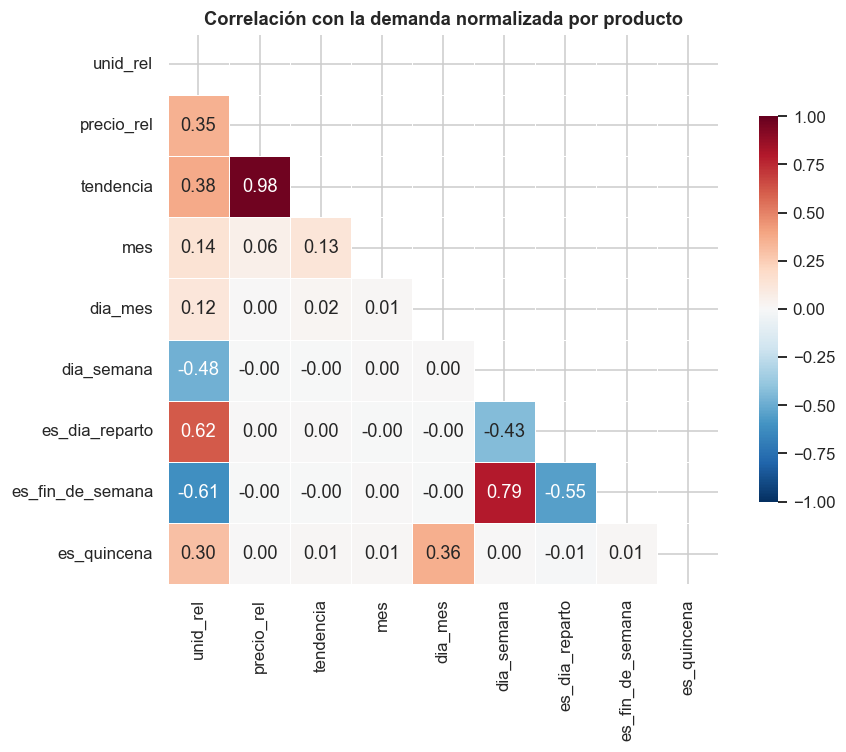

Correlación de cada variable con la demanda relativa (ordenada por magnitud):


,pearson
es_dia_reparto,0.62
es_fin_de_semana,-0.61
dia_semana,-0.48
tendencia,0.38
precio_rel,0.35
es_quincena,0.30
mes,0.14
dia_mes,0.12


In [25]:
vars_rel = ["unid_rel", "precio_unitario", "tendencia", "mes", "dia_mes", "dia_semana", "es_dia_reparto", "es_fin_de_semana", "es_quincena"]
# precio relativo al promedio del propio producto, para quitar la escala entre productos
df["precio_rel"] = df["precio_unitario"] / df.groupby("producto")["precio_unitario"].transform("mean")
vars_rel = [v if v != "precio_unitario" else "precio_rel" for v in vars_rel]
corr_rel = df[vars_rel].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr_rel, mask=np.triu(np.ones_like(corr_rel, dtype=bool)), cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", linewidths=.4, square=True, cbar_kws={"shrink": .7})
plt.title("Correlación con la demanda normalizada por producto"); plt.tight_layout(); plt.show()

print("Correlación de cada variable con la demanda relativa (ordenada por magnitud):")
display(corr_rel["unid_rel"].drop("unid_rel").sort_values(key=abs, ascending=False).to_frame("pearson"))

**Notas de interpretación**
- `total` correlaciona casi perfectamente con `unidades` porque se calcula a partir de ella → **se excluye del modelo** (fuga de información).
- `dia_semana` y `es_fin_de_semana` / `es_dia_reparto` miden la misma información desde ángulos distintos; esa **multicolinealidad** no afecta a modelos de árboles, pero sí a una regresión lineal (se resuelve con codificación por días o regularización).
- `precio_unitario` y `tendencia` suelen correlacionar porque el precio sube con el tiempo (inflación): su relación con las ventas puede ser **espuria** (confusión por el tiempo) y debe interpretarse con cuidado.

## 7.2 Pruebas de hipótesis sobre los patrones de calendario

In [26]:
# Quincena vs día normal (Mann-Whitney: no asume normalidad)
a = df.loc[df["es_quincena"] == 1, "unid_rel"]; b = df.loc[df["es_quincena"] == 0, "unid_rel"]
u = stats.mannwhitneyu(a, b, alternative="greater")
print(f"Quincena vs día normal   : media relativa {a.mean():.3f} vs {b.mean():.3f}  (+{(a.mean()/b.mean()-1)*100:.1f} %)   Mann-Whitney p = {u.pvalue:.2e}")

# Días de reparto vs resto
a = df.loc[df["es_dia_reparto"] == 1, "unid_rel"]; b = df.loc[df["es_dia_reparto"] == 0, "unid_rel"]
u = stats.mannwhitneyu(a, b, alternative="greater")
print(f"Reparto (L-M-V) vs resto : media relativa {a.mean():.3f} vs {b.mean():.3f}  (+{(a.mean()/b.mean()-1)*100:.1f} %)   Mann-Whitney p = {u.pvalue:.2e}")

# Entre los 7 días de la semana (Kruskal-Wallis)
h = stats.kruskal(*[g["unid_rel"].values for _, g in df.groupby("dia_semana")])
print(f"Entre días de la semana  : Kruskal-Wallis H = {h.statistic:,.1f}  p = {h.pvalue:.2e}")

# Entre familias
h2 = stats.kruskal(*[g["unid_rel"].values for _, g in df.groupby("mes")])
print(f"Entre meses              : Kruskal-Wallis H = {h2.statistic:,.1f}  p = {h2.pvalue:.2e}")
print("\nSi p < 0.05 el patrón es estadísticamente significativo y debe incluirse como variable explicativa.")

Quincena vs día normal   : media relativa 1.200 vs 0.936  (+28.2 %)   Mann-Whitney p = 1.06e-258
Reparto (L-M-V) vs resto : media relativa 1.267 vs 0.800  (+58.4 %)   Mann-Whitney p = 0.00e+00
Entre días de la semana  : Kruskal-Wallis H = 9,080.7  p = 0.00e+00
Entre meses              : Kruskal-Wallis H = 492.7  p = 1.18e-98

Si p < 0.05 el patrón es estadísticamente significativo y debe incluirse como variable explicativa.


---
# 8. Prototipo de la solución: pronóstico y recomendación de pedido

Esta sección demuestra que el problema es **predecible** y que el pronóstico se puede convertir en una decisión de compra. Es un prototipo; el modelado completo y su validación corresponden a los siguientes avances.

**Diseño sin fuga de información:** se pronostica con **14 días de anticipación**, por lo que los rezagos de ventas usados son de al menos 14 días. La validación es **temporal** (se entrena con el pasado y se prueba con los últimos días), nunca aleatoria.

In [27]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

H = 14   # horizonte de pronóstico en días
d = df.sort_values(["producto", "fecha"]).copy()
g = d.groupby("producto")["unidades"]
d["lag_14"] = g.shift(H)
d["lag_21"] = g.shift(H + 7)
d["media_28_lag14"] = g.transform(lambda s: s.shift(H).rolling(28, min_periods=14).mean())
d["prod_cod"] = d["producto"].astype("category").cat.codes

FEATURES = ["prod_cod", "precio_unitario", "dia_semana", "dia_mes", "mes", "es_quincena", "es_dia_reparto", "tendencia",
            "lag_14", "lag_21", "media_28_lag14"]
d = d.dropna(subset=FEATURES)

n_test_dias = min(90, int(d["fecha"].nunique() * 0.2))
corte = d["fecha"].max() - pd.Timedelta(days=n_test_dias - 1)
train, test = d[d["fecha"] < corte], d[d["fecha"] >= corte]
print(f"Entrenamiento: {len(train):,} registros ({train['fecha'].min():%Y-%m-%d} → {train['fecha'].max():%Y-%m-%d})")
print(f"Prueba       : {len(test):,} registros ({test['fecha'].min():%Y-%m-%d} → {test['fecha'].max():%Y-%m-%d})")

modelo = HistGradientBoostingRegressor(max_iter=400, learning_rate=.05, max_depth=6, l2_regularization=1.0,
                                       categorical_features=[FEATURES.index("prod_cod")], random_state=7)
modelo.fit(train[FEATURES], train["unidades"])
test = test.assign(pred=np.clip(modelo.predict(test[FEATURES]), 0, None))

def metricas(y, p):
    e = y - p
    return {"MAE": np.abs(e).mean(), "RMSE": np.sqrt((e ** 2).mean()), "WAPE (%)": np.abs(e).sum() / y.sum() * 100,
            "R²": 1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum()}

tabla_m = pd.DataFrame({
    "Referencia: ventas de hace 14 días": metricas(test["unidades"], test["lag_14"]),
    "Referencia: promedio móvil 28 días": metricas(test["unidades"], test["media_28_lag14"]),
    "Modelo (Gradient Boosting)": metricas(test["unidades"], test["pred"]),
}).T
display(tabla_m)
mejora = (1 - tabla_m.loc["Modelo (Gradient Boosting)", "WAPE (%)"] / tabla_m.loc["Referencia: ventas de hace 14 días", "WAPE (%)"]) * 100
print(f"Reducción del error (WAPE) frente a la referencia de hace 14 días: {mejora:.1f} %")

Entrenamiento: 15,024 registros (2023-01-28 → 2026-07-02)
Prueba       : 1,080 registros (2026-07-03 → 2026-09-30)


,MAE,RMSE,WAPE (%),R²
Referencia: ventas de hace 14 días,5.11,7.30,16.67,0.82
Referencia: promedio móvil 28 días,8.18,10.80,26.70,0.61
Modelo (Gradient Boosting),3.37,4.87,11.00,0.92


Reducción del error (WAPE) frente a la referencia de hace 14 días: 34.0 %


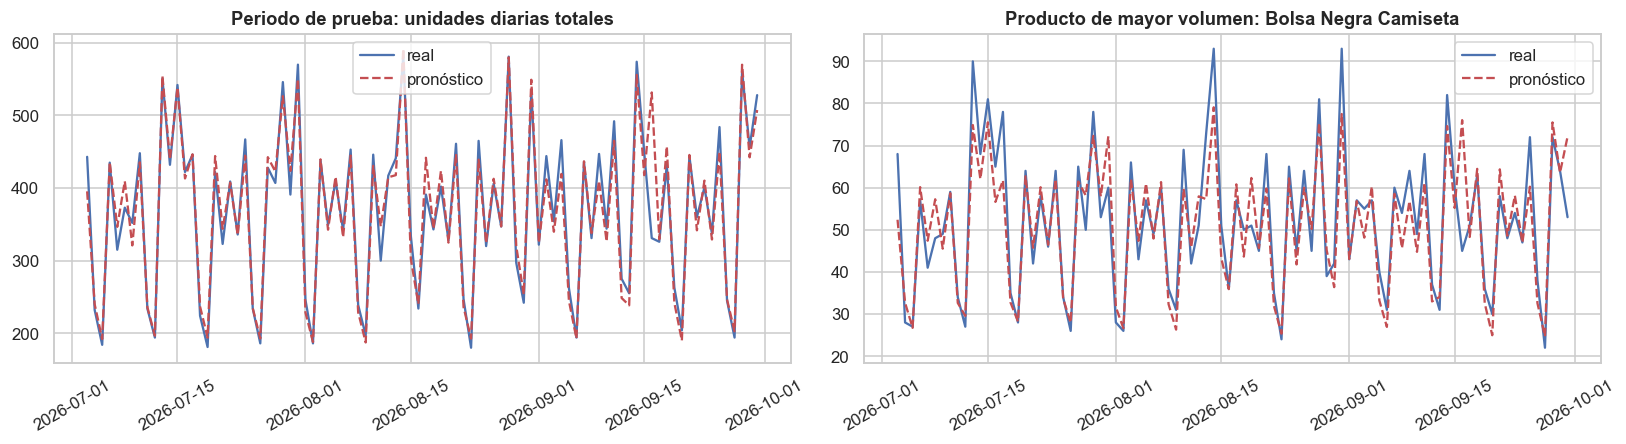

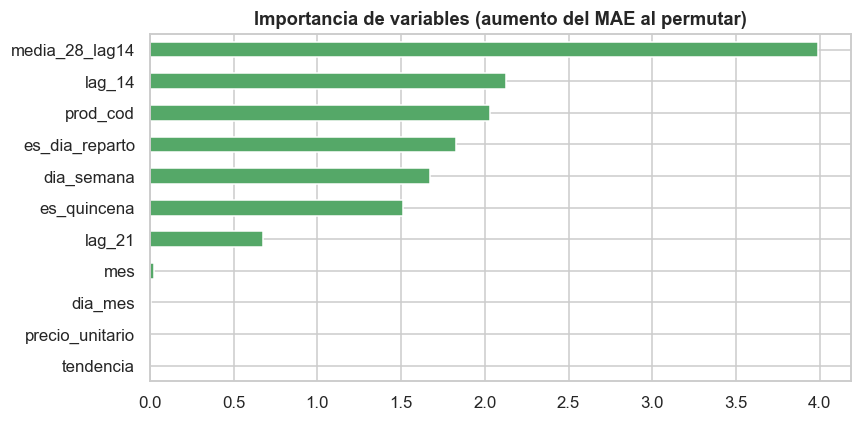

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
tot = test.groupby("fecha")[["unidades", "pred"]].sum()
ax[0].plot(tot.index, tot["unidades"], label="real", color="#4c72b0"); ax[0].plot(tot.index, tot["pred"], label="pronóstico", color="#c44e52", ls="--")
ax[0].set_title("Periodo de prueba: unidades diarias totales"); ax[0].legend(); ax[0].tick_params(axis="x", rotation=30)

estrella = test.groupby("producto")["unidades"].sum().idxmax()
e = test[test["producto"] == estrella]
ax[1].plot(e["fecha"], e["unidades"], label="real", color="#4c72b0"); ax[1].plot(e["fecha"], e["pred"], label="pronóstico", color="#c44e52", ls="--")
ax[1].set_title(f"Producto de mayor volumen: {estrella}"); ax[1].legend(); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

imp = permutation_importance(modelo, test[FEATURES], test["unidades"], n_repeats=5, random_state=7, scoring="neg_mean_absolute_error")
imp_s = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
plt.figure(figsize=(8, 4)); imp_s.plot(kind="barh", color="#55a868"); plt.title("Importancia de variables (aumento del MAE al permutar)")
plt.tight_layout(); plt.show()

### Recomendación de pedido a 14 días

Para cada producto: **pedido sugerido = pronóstico de demanda de los próximos 14 días + stock de seguridad − inventario disponible**.  
El stock de seguridad se calcula con el error del modelo: `z × σ_error_diario × √14`, con `z = 1.65` (≈ 95 % de nivel de servicio).

In [29]:
# Construir los próximos 14 días y pronosticar con la misma lógica de rezagos
ultimo = d["fecha"].max()
fut_fechas = pd.date_range(ultimo + pd.Timedelta(days=1), periods=H, freq="D")
base = df.sort_values(["producto", "fecha"])[["fecha", "producto", "unidades", "precio_unitario", "tendencia"]].copy()
ult_precio = base.groupby("producto")["precio_unitario"].last()
futuro = pd.DataFrame([(f, p) for p in base["producto"].unique() for f in fut_fechas], columns=["fecha", "producto"])
futuro["precio_unitario"] = futuro["producto"].map(ult_precio)
futuro["unidades"] = np.nan
futuro["tendencia"] = (futuro["fecha"] - df["fecha"].min()).dt.days
comb = pd.concat([base[["fecha", "producto", "unidades", "precio_unitario", "tendencia"]], futuro], ignore_index=True).sort_values(["producto", "fecha"])
comb["dia_semana"] = comb["fecha"].dt.weekday; comb["dia_mes"] = comb["fecha"].dt.day; comb["mes"] = comb["fecha"].dt.month
comb["es_quincena"] = (comb["dia_mes"].between(13, 16) | (comb["dia_mes"] >= 28)).astype(int)
comb["es_dia_reparto"] = comb["dia_semana"].isin([0, 2, 4]).astype(int)
gg = comb.groupby("producto")["unidades"]
comb["lag_14"] = gg.shift(H); comb["lag_21"] = gg.shift(H + 7)
comb["media_28_lag14"] = gg.transform(lambda s: s.shift(H).rolling(28, min_periods=14).mean())
comb["prod_cod"] = pd.Categorical(comb["producto"], categories=d["producto"].astype("category").cat.categories).codes
fut = comb[comb["fecha"] > ultimo].copy()
fut["pred"] = np.clip(modelo.predict(fut[FEATURES]), 0, None)

sigma = (test["unidades"] - test["pred"]).groupby(test["producto"]).std()
Z = 1.65
rec = fut.groupby("producto")["pred"].sum().to_frame("pronóstico 14 días")
rec["stock de seguridad"] = (Z * sigma * np.sqrt(H)).reindex(rec.index)
rec["inventario disponible"] = 0          # ← capturar aquí el inventario real de cada producto (o reemplazar con el dato del POS)
rec["pedido sugerido"] = (rec["pronóstico 14 días"] + rec["stock de seguridad"] - rec["inventario disponible"]).clip(lower=0)
rec = rec.round(0).astype(int).sort_values("pedido sugerido", ascending=False)
print(f"Pronóstico del {fut_fechas[0]:%Y-%m-%d} al {fut_fechas[-1]:%Y-%m-%d}")
display(rec)

Pronóstico del 2026-10-01 al 2026-10-14


,pronóstico 14 días,stock de seguridad,inventario disponible,pedido sugerido
producto,,,,
Bolsa Negra Camiseta,683,45,0,728
Bolsa Camiseta Poliseda,599,41,0,640
Bolsa Rollo Baja Densidad,596,41,0,637
Bolsa Basura Todos Tamanios,545,33,0,579
Bolsa Rollo Alta Densidad,525,29,0,554
Bolsa Rollo Poliseda,480,29,0,509
Bolsa Camiseta Color,428,30,0,458
Bolsa Camiseta Plata,376,26,0,402
Pelicula Plastica Emplaye,248,17,0,265


---
# 9. Hallazgos principales

In [30]:
q_lift = df.loc[df["es_quincena"] == 1, "unid_rel"].mean() / df.loc[df["es_quincena"] == 0, "unid_rel"].mean() - 1
rep_lift = df.loc[df["es_dia_reparto"] == 1, "unid_rel"].mean() / df.loc[df["es_dia_reparto"] == 0, "unid_rel"].mean() - 1
mejor_dia = df.groupby("nombre_dia")["unid_rel"].mean().idxmax(); peor_dia = df.groupby("nombre_dia")["unid_rel"].mean().idxmin()
mes_pico = df.groupby("mes")["unid_rel"].mean().idxmax()
top3 = por_prod["% ingresos"].sort_values(ascending=False).head(3)
baja = por_prod["media"].sort_values().head(3).index.tolist()
crec = (serie.iloc[-6:].mean() / serie.iloc[:6].mean() - 1) * 100

print(f"1. Calidad de datos: {len(raw):,} registros crudos → {len(df):,} limpios; se corrigió el {resumen_limpieza['Registros afectados'].sum()/len(raw)*100:.1f} % de los registros.")
print(f"2. Quincena: las ventas son {q_lift*100:+.1f} % mayores que en un día normal.")
print(f"3. Días de reparto (lun, mié, vie): {rep_lift*100:+.1f} % frente al resto. Día más alto: {mejor_dia}; más bajo: {peor_dia}.")
print(f"4. Estacionalidad: el mes de mayor demanda relativa es el mes {mes_pico}.")
print(f"5. Concentración: los 3 productos con más ingresos suman {top3.sum():.1f} % de las ventas ({', '.join(top3.index)}).")
print(f"6. Baja rotación (riesgo de capital inmovilizado): {', '.join(baja)}.")
print(f"7. Tendencia: el promedio de los últimos 6 meses es {crec:+.1f} % frente a los primeros 6 meses del historial.")
print(f"8. Predicción: el modelo reduce el WAPE {mejora:.1f} % frente a repetir lo vendido hace 14 días (WAPE modelo = {tabla_m.loc['Modelo (Gradient Boosting)','WAPE (%)']:.1f} %).")

1. Calidad de datos: 16,498 registros crudos → 16,428 limpios; se corrigió el 1.8 % de los registros.
2. Quincena: las ventas son +28.2 % mayores que en un día normal.
3. Días de reparto (lun, mié, vie): +58.4 % frente al resto. Día más alto: Vie; más bajo: Dom.
4. Estacionalidad: el mes de mayor demanda relativa es el mes 12.
5. Concentración: los 3 productos con más ingresos suman 35.3 % de las ventas (Bolsa Negra Camiseta, Bolsa Basura Todos Tamanios, Bolsa Camiseta Poliseda).
6. Baja rotación (riesgo de capital inmovilizado): Contenedor Termico Unicel, Charolas Desechables, Vasos Desechables.
7. Tendencia: el promedio de los últimos 6 meses es +57.7 % frente a los primeros 6 meses del historial.
8. Predicción: el modelo reduce el WAPE 34.0 % frente a repetir lo vendido hace 14 días (WAPE modelo = 11.0 %).


## Conclusiones y siguientes pasos

1. **El problema es relevante y medible:** la demanda de plásticos de consumo tiene ritmos claros (semana, quincena, temporada) que hoy no se aprovechan en la decisión de compra.
2. **La variable objetivo `unidades` es predecible** con variables de calendario, precio y rezagos de ventas, y supera una referencia simple (EDA y sección 8).
3. **Decisiones de preparación de datos** justificadas: estandarización de nombres, eliminación de duplicados por clave de negocio, corrección de signo, imputación por mediana contextual (producto × día × quincena), y recálculo de `total`.
4. **Para el Avance 2:** comparar modelos (regresión regularizada, Random Forest, Gradient Boosting, y modelos de series de tiempo), validación temporal con múltiples cortes (*walk-forward*), ajuste de hiperparámetros y evaluación económica (quiebres evitados y capital liberado).